# <font color='#GGE15D'>**Clustering: Kmeans**</font>

## **🔸 Imports**

In [74]:
!#pip install mlxtend

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_blobs
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.cluster import *

from mlxtend.plotting import plot_decision_regions

from pathlib import Path

'#pip' is not recognized as an internal or external command,
operable program or batch file.


## **🔸 Datasets**

<font color='#EE15D'> **Note: This assignment contains 4 datasets. Example 1 is the Mall Customers dataset. Examples 2, 3, and 4 are three generated datasets.**

### Example 1

In [75]:
data_path = Path("data") / "Mall_Customers.csv"

X = pd.read_csv(data_path)
X.columns = ['customer_id', 'gender', 'age', 'annual_income', 'spending_score']
X = X.drop('customer_id', axis=1)
X['gender'] = X['gender'].map({'Male': 0, 'Female': 1})
display(X.head())


X_train, X_test = train_test_split(X, test_size=0.2, random_state=0)

X_train = X_train.values
X_test = X_test.values

X_train.shape, X_test.shape

,gender,age,annual_income,spending_score
0,0,19,15,39
1,0,21,15,81
2,1,20,16,6
3,1,23,16,77
4,1,31,17,40


((160, 4), (40, 4))

In [76]:
X.columns[-1], X.columns[-2]

('spending_score', 'annual_income')

Text(0, 0.5, 'spending_score')

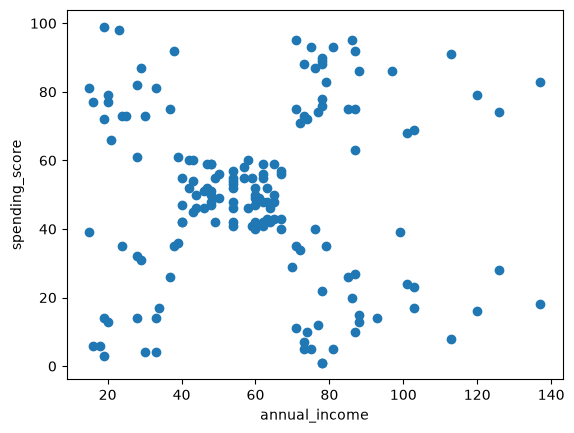

In [77]:
plt.scatter(X_train[:, -2], X_train[:, -1])
plt.xlabel(X.columns[-2])
plt.ylabel(X.columns[-1])

### Example 2

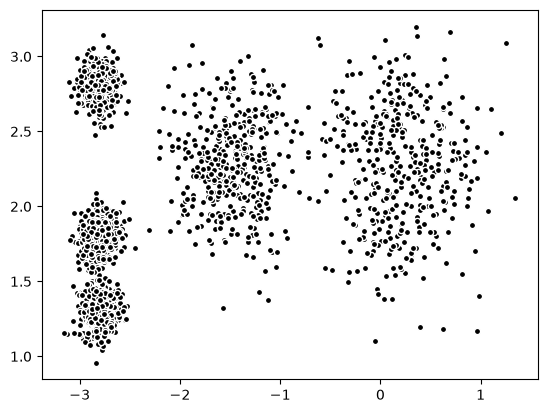

In [78]:
blob_centers = np.array([[ 0.2,  2.3],
                         [-1.5,  2.3],
                         [-2.8,  1.8],
                         [-2.8,  2.8],
                         [-2.8,  1.3]])

blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

X2, y2 = make_blobs(n_samples=2000, centers=blob_centers,
                  cluster_std=blob_std, random_state=7)

plt.scatter(X2[:, 0], X2[:, 1], s=20, c='black', edgecolor='white')

### Example 3

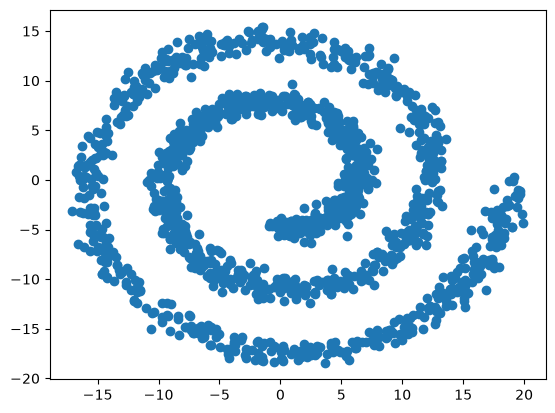

In [79]:
n_samples = 1500
np.random.seed(0)

t = 1.5 * np.pi * (1 + 3 * np.random.rand(1, n_samples))
x = t * np.cos(t)
y = t * np.sin(t)

X3 = np.concatenate((x, y))
X3 += 0.7 * np.random.randn(2, n_samples)
X3 = X3.T

plt.scatter(X3[:, 0], X3[:, 1])

### Example 4

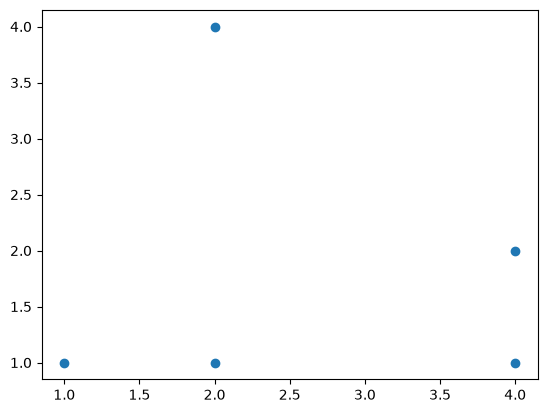

In [80]:
X4 = np.array([[1, 1], [2, 4], [2, 1], [4, 1], [4, 2]])

plt.scatter(X4[:, 0], X4[:, 1])

## **🔸 K-means**

### sklearn

In [81]:
cols = ['gender', 'age', 'annual_income', 'spending_score']
idx = [2, 3]
X = X_train[:, idx].copy()

In [82]:
X.shape

(160, 2)

<font color='#EE15D'>**Question1: Import Kmeans, Consider 3 different numbers of clusters: 2, 3, and 5 on X dataset. Finally, visualize the results and compare the plots.**

In [83]:
cluster_nums = [2, 3, 5]
models = {}

for n in cluster_nums:
    print("\nNumber of clusters, k:", n)
    models[n] = KMeans(n_clusters=n, random_state=0, n_init=10).fit(X)
    print("Dimensions of trained X:", models[n].labels_.shape)
    print("Dimensions of cluster centers:", models[n].cluster_centers_.shape)
    



Number of clusters, k: 2
Dimensions of trained X: (160,)
Dimensions of cluster centers: (2, 2)

Number of clusters, k: 3
Dimensions of trained X: (160,)
Dimensions of cluster centers: (3, 2)

Number of clusters, k: 5
Dimensions of trained X: (160,)
Dimensions of cluster centers: (5, 2)


In [84]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

C:\Users\MY NGOC\AppData\Local\Temp\ipykernel_8064\626639533.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\MY NGOC\AppData\Local\Temp\ipykernel_8064\626639533.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\MY NGOC\AppData\Local\Temp\ipykernel_8064\626639533.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


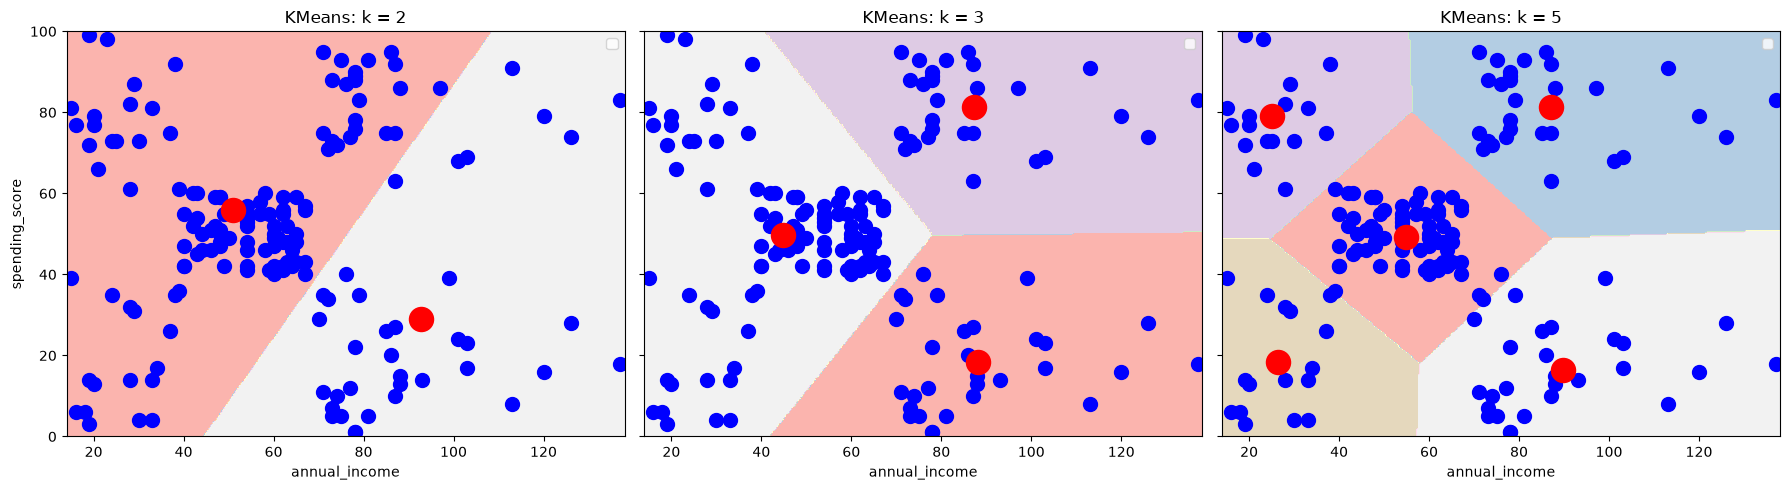

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, n in zip(axes, cluster_nums):
    kmeans = models[n]
    labels = kmeans.labels_
    centroids = kmeans.cluster_centers_
    Xm = kmeans.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Xm, cmap=plt.cm.Pastel1)
    ax.scatter(X[:, 0], X[:, 1], s=100, c='blue')
    ax.scatter(centroids[: , 0], centroids[: , 1], s=300, c='red')

    ax.set_title(f'KMeans: k = {n}')
    ax.set_xlabel(cols[idx[0]])
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.legend()

axes[0].set_ylabel(cols[idx[1]])
fig.tight_layout()
plt.show()


**Answer for Question 1**:
For k=2, the method divides customers into 2 broad groups. Customers with substantially different income and spending patterns are group together, failing to capture the underlying structure. It shows underfitting because there are too few clusters to distinguish meaningful customer segments.

For k =3, it provides better separation, particularly between high and low spending customers with higher income. However, customers with low incomes and very different spending scores are still grouped together with the dense central group.

For k=5, it identifies 5 relatively distinct customer segments: 
- low-income/high-spending, 
- low-income/low-spending, 
- medium-income/medium spending,
- high-income/high-spending,
- and high income/low-spending.
The cluster centroids align better with the apparent structure of the dataset with more meaningful and interpretable customer segments.

However, it is not certain to establish that k=5 is statistically optimal by visual inspection. Quantitative measures such as silhouette score and elbow method should also be considered to assess cluster separation and compactness. 

## **🔸 Elbow & Silhouette**

<font color='#EE15D'> **Question2: Elbow: Write code to compute and plot the elbow curve for the X dataset. Your final plot should match the provided output. Determine where the elbow point is.**

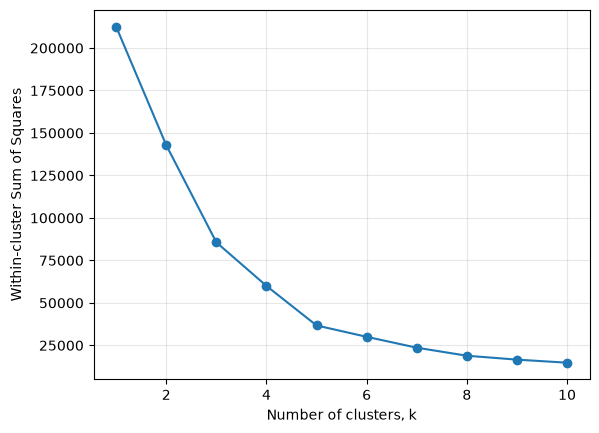

In [86]:
from matplotlib.lines import lineStyles


ks = range(1,11)
#within-cluster SS
wcss = []
models_ks = {}

for k in ks:
    models_ks[k] = KMeans(n_clusters=k, random_state=42, n_init=10)
    models_ks[k].fit(X)
    wcss.append(models_ks[k].inertia_)
    
fig,ax = plt.subplots(nrows=1, ncols=1)
ax.plot(ks, wcss, marker='o', linestyle="-")
ax.set_xlabel('Number of clusters, k')
ax.set_ylabel("Within-cluster Sum of Squares")
ax.grid(alpha=0.3)
plt.show()

**Answer for Question 2**:
The elbow point is approximately k=5, where the rate of decrease in Within-cluster Sum of Squares becomes noticeably smaller. Increasing the number of clusters, k beyond 5 provides relatively small improvement. Therefore, k=5 is a reasonable choice for optimal number of clusters, which is consistent the 5 visually distinct groups plotted in Question 1.

### Silhouette score

<font color='#EE15D'> **Question3: Calculate sillhoutte score**

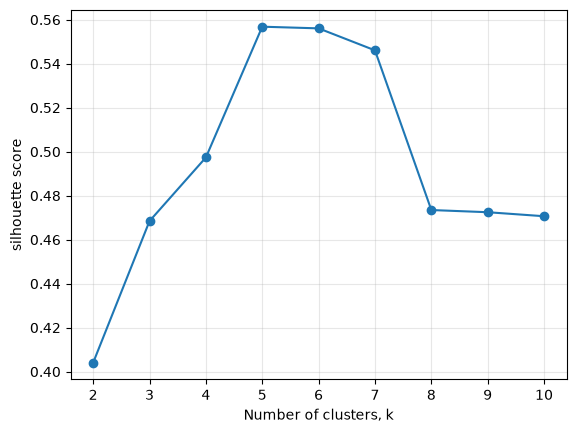

In [87]:
sillh_scores = []
ks = [k for k in ks if k>=2]

for k in ks:
    labels = models_ks[k].fit_predict(X)
    sillh_scores.append(silhouette_score(X, labels)) 
    
fig,ax = plt.subplots(nrows=1, ncols=1)
ax.plot(ks, sillh_scores, marker='o', linestyle="-")
ax.set_xlabel('Number of clusters, k')
ax.set_ylabel("silhouette score")
ax.grid(alpha=0.3)
plt.show()

## **🔸 Hierarchical Clustering**

### Example 1

<font color='#EE15D'> **Question4: Use AgglomerativeClustering of Sklearn with 5 clusters, fit on X2 data and plot it. You just need to complete agg code line**

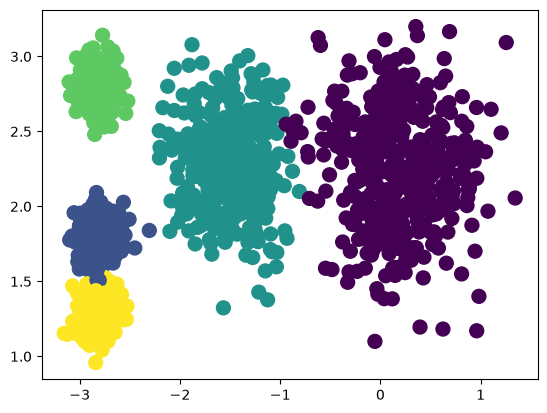

In [88]:
agg = AgglomerativeClustering(n_clusters=5)
agg.fit(X2)

labels = agg.labels_


plt.scatter(X2[:, 0], X2[:, 1], s=100, c=labels);

### Example 2

<font color='#EE15D'> **Question5: Apply AgglomerativeClustering on X data with 5 clusters, switch linkage between 'ward', 'single', and 'complete' and compare the plotts. Which is a better method?**

In [89]:
cols = ['gender', 'age', 'annual_income', 'spending_score']
idx = [2, 3]
X = X_train[:, idx].copy()

C:\Users\MY NGOC\AppData\Local\Temp\ipykernel_8064\2270317976.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


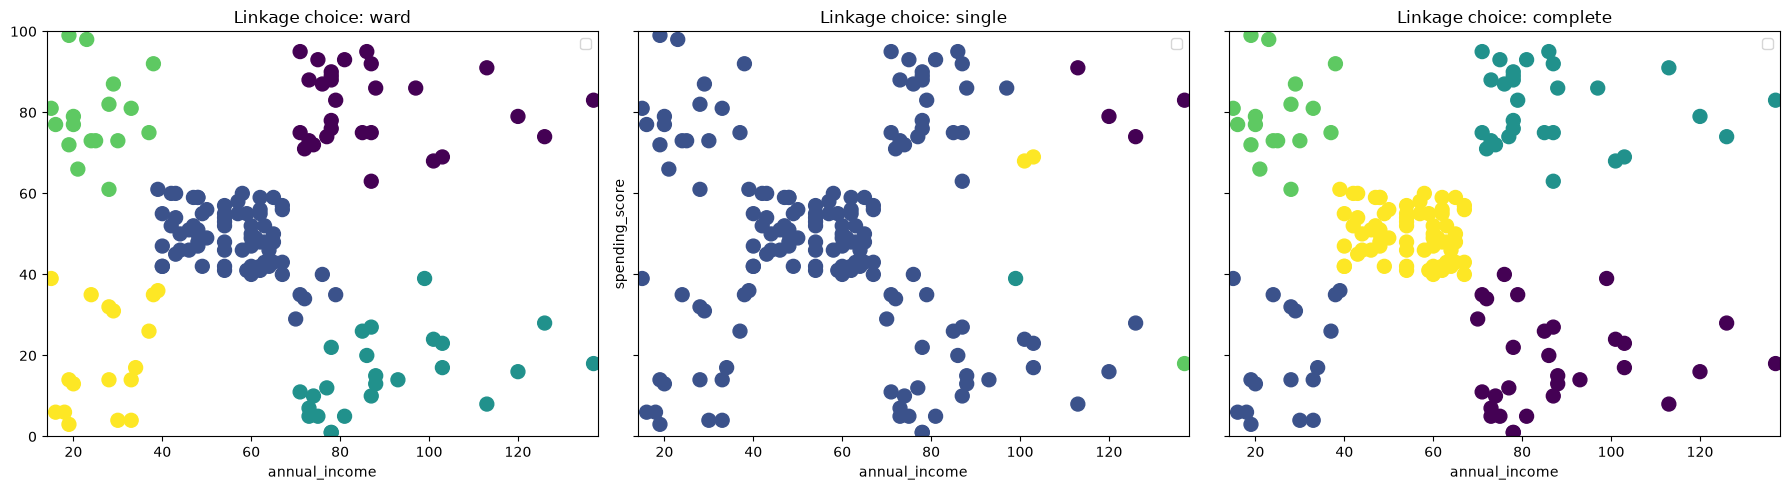

In [90]:
linkages = ["ward", "single", "complete"]
agg_models = {}

fig, axes = plt.subplots(nrows=1, ncols=len(linkages), figsize=(18,5),sharex=True, sharey=True)

for linkage in linkages:
    agg_models[linkage] =  AgglomerativeClustering(n_clusters=5, linkage=linkage)
    agg_models[linkage].fit(X)

for ax, l in zip(axes, linkages):
    labels = agg_models[l].labels_
    ax.scatter(X[:, 0], X[:, 1], s=100, c=labels,)
    
    ax.set_title(f'Linkage choice: {l}')
    ax.set_xlabel(cols[idx[0]])
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.legend()

axes[len(linkages)//2].set_ylabel(cols[idx[1]])

fig.tight_layout()
plt.show()

**Answer for Question 5**: Which is a better method?
Complete leakage appears to be the best model, as shown in the plots. It separates the 5 visible groups clearly. Ward gives similar groups with some differences near cluster boundaries. Single linkage gives less useful results because it merges most observations into one cluster and appears to be too sensitive to noises.

They behave differently because they use different rules to decide which 2 clusters to merge. All start with each point as its own cluster and keep merging until 5 clusters are achieved.

- Single linkage: Uses distance between the closest pair of points, one from each cluster. It can connect large groups through a chain of nearby points. A single nearby pair is enough to merge 2 clusters, even if their other points are far apart. In this data, intermediate points create connections between the visible groups. This chaining effect put most observations into one large cluster. A few isolated points remain separate, so requesting 5 clusters produces 1 large cluster and several tiny ones.
- Complete linkage: Uses distance between the farthest pair of points, one from each cluster. It favors groups whose points are all reasonably close together. 
- Ward: Chooses the merge that causes the smallest increase in within-cluster sum of squared distances. It favors compact groups with low internal variation. Ward considers how much a merge increases the total squared distance around cluster means. The 5 visible groups are relatively compact, so it also recovers that general structure. However, its decision depends on the cluster sizes and the locations of all points.


### Example 3

<font color='#EE15D'> **Question6: Apply AgglomerativeClustering on X3 data with 4 clusters, and linkage = 'ward', finally visualize it**

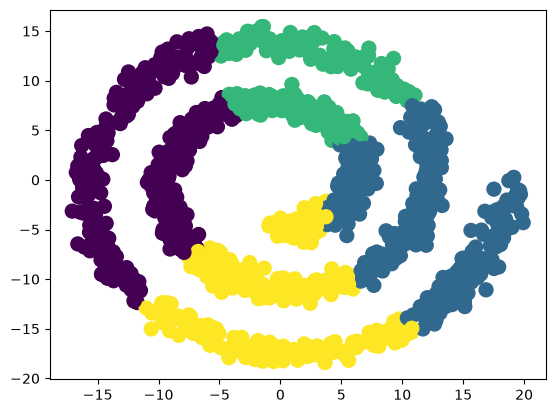

In [91]:
agg = AgglomerativeClustering(n_clusters=4, linkage="ward")  #complete this code
agg.fit(X3)

labels = agg.labels_


plt.scatter(X3[:, 0], X3[:, 1], s=100, c=labels);

**Answers for Question 6**: 
Ward linkage gives 4 clusters. but they do not follow the curves shapes in the data. Its preference for compact clusters leads it to divide the curves into spatial regions.

### Dendrogram (Optional, Extra point)

For extra points, you can plot a dendrogram using Agglomerative Clustering on the X4 dataset by applying the function provided in the following link.

https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html

In [92]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram

from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris


def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)



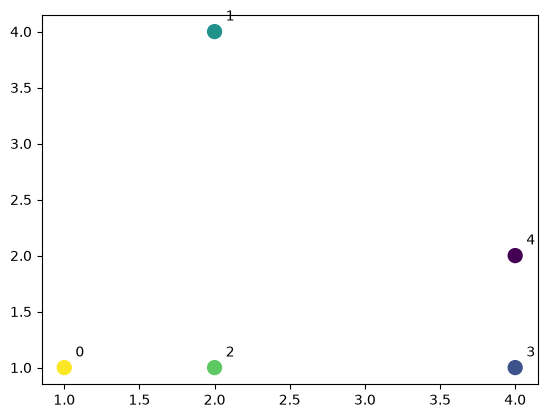

In [96]:
# Build the full hierarchy and record the merge distances.
agg_X4 = AgglomerativeClustering(
    n_clusters=None, distance_threshold=0, linkage="ward"
).fit(X4)
labels_X4 = agg_X4.labels_
plt.scatter(X4[:, 0], X4[:, 1], s=100, c=labels_X4)

for i, (x,y) in enumerate(X4):
    plt.annotate(str(i), (x,y), xytext=(8,8), textcoords="offset points")
    


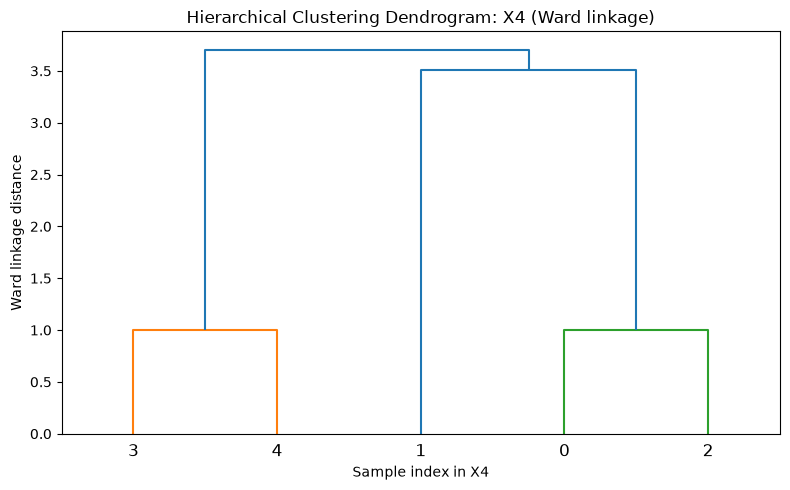

In [97]:
plt.figure(figsize=(8, 5))
plot_dendrogram(agg_X4, labels=[str(i) for i in range(len(X4))])
plt.title("Hierarchical Clustering Dendrogram: X4 (Ward linkage)")
plt.xlabel("Sample index in X4")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()